# 2026 CITS4012 Project
**Group ID: 58**

# Readme
*If there is something to be noted for the marker, please mention here.*

*If you are planning to implement a program with Object Oriented Programming style, please put those the bottom of this ipynb file*

# 1.Dataset Processing
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'train.jsonl', 'best_model.pt', 'ablation1_no_attention.pt', 'attention_example_3.png', 'attention_example_0.png', 'attention_example_2.png', 'attention_example_1.png', 'test-labels.lst', 'training_curves.png', 'test.jsonl', 'train-labels.lst', 'ablation2_unigru.pt', 'sample_data']


In [ ]:
TRAIN_FILE = "/content/train.jsonl"
TRAIN_LABELS = "/content/train-labels.lst"

TEST_FILE = "/content/test.jsonl"
TEST_LABELS = "/content/test-labels.lst"

In [ ]:
import json

train_examples = []

with open(TRAIN_FILE, "r") as f:
    for line in f:
        train_examples.append(json.loads(line))

with open(TRAIN_LABELS, "r") as f:
    train_labels = [int(line.strip()) for line in f]

print("Training examples:", len(train_examples))
print("Training labels:", len(train_labels))

Training examples: 16113
Training labels: 16113


In [ ]:
import random

random.seed(42)
indices = list(range(len(train_examples)))
random.shuffle(indices)

val_size = int(0.1 * len(indices))
val_indices = set(indices[:val_size])

val_examples = [train_examples[i] for i in val_indices]
val_labels = [train_labels[i] for i in val_indices]

train_examples = [train_examples[i] for i in indices[val_size:]]
train_labels = [train_labels[i] for i in indices[val_size:]]

print("Train:", len(train_examples))
print("Val:", len(val_examples))

Train: 14502
Val: 1611


In [ ]:
print("Goal:", train_examples[0]["goal"])
print("Solution 1:", train_examples[0]["sol1"])
print("Solution 2:", train_examples[0]["sol2"])
print("Label:", train_labels[0])

Goal: Reduce amount of unpopped kernels.
Solution 1: Soak kernels in water for a few minutes before cooking.
Solution 2: Soak kernels in water for a few hours before cooking.
Label: 0


## 1.1 Loading the Validation Set

The dataset folder also provides a labelled evaluation split (`test.jsonl` /
`test-labels.lst`). This size (1,838 examples) matches the official PIQA
validation set rather than the hidden test set, so it is treated as
validation data throughout this project and used only for model selection,
never for training.

In [ ]:
test_examples = []
with open(TEST_FILE, "r") as f:
    for line in f:
        test_examples.append(json.loads(line))

with open(TEST_LABELS, "r") as f:
    test_labels = [int(line.strip()) for line in f]

print("Test examples:", len(test_examples))
print("Test labels:", len(test_labels))

Test examples: 1838
Test labels: 1838


## 1.2 Tokenisation

Text is lowercased and split into alphanumeric tokens using a simple regex
tokeniser. Contractions (e.g. "it's") are split into separate tokens
(e.g. "it", "s"), a standard simplification for training embeddings from
scratch.

In [ ]:
import re

def tokenize(text):
    text = text.lower()
    tokens = re.findall(r"[a-z0-9]+", text)
    return tokens

In [ ]:
print(tokenize(train_examples[0]["goal"]))

['reduce', 'amount', 'of', 'unpopped', 'kernels']


## 1.3 Vocabulary Construction

A vocabulary is built from the training set only, to avoid validation-set
leakage. Words appearing fewer than `MIN_FREQ=2` times are mapped to an
`<UNK>` token, and index 0 is reserved for `<PAD>`. This produced a
vocabulary of 11,530 tokens.

In [ ]:
# building the vocabulary:
from collections import Counter

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
MIN_FREQ = 2

def build_vocab(examples, min_freq=MIN_FREQ):
    counter = Counter()
    for ex in examples:
        counter.update(tokenize(ex["goal"]))
        counter.update(tokenize(ex["sol1"]))
        counter.update(tokenize(ex["sol2"]))

    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for word, freq in counter.items():
        if freq >= min_freq:
            vocab[word] = len(vocab)

    return vocab

vocab = build_vocab(train_examples)

vocab_size = len(vocab)
pad_idx = vocab[PAD_TOKEN]

print("Vocabulary size:", vocab_size)
print("Padding index:", pad_idx)

Vocabulary size: 11015
Padding index: 0


## 1.4 Text-to-ID Encoding

Each sequence is encoded into vocabulary IDs and truncated to a maximum of
`MAX_LEN=40` tokens. This cap was chosen after inspecting the solution
length distribution (mean ≈19 tokens, max ≈390), to avoid excessive padding
from rare long outliers.

In [ ]:
MAX_LEN = 40  # covers the vast majority of examples without wasting compute on rare outliers

def encode(text, vocab, max_len=MAX_LEN):
    ids = [vocab.get(tok, vocab[UNK_TOKEN]) for tok in tokenize(text)]
    return ids[:max_len]

In [ ]:
print(encode(train_examples[0]["goal"], vocab))

[2, 3, 4, 5, 6]


## 1.5 PyTorch Dataset

`PIQADataset` wraps the encoding step so each example is converted to token
IDs on access, returning `(goal_ids, sol1_ids, sol2_ids, label)`.

In [ ]:
from torch.utils.data import Dataset

class PIQADataset(Dataset):
    def __init__(self, examples, labels, vocab):
        self.examples = examples
        self.labels = labels
        self.vocab = vocab

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        ex = self.examples[idx]
        goal_ids = encode(ex["goal"], self.vocab)
        sol1_ids = encode(ex["sol1"], self.vocab)
        sol2_ids = encode(ex["sol2"], self.vocab)
        label = self.labels[idx]
        return goal_ids, sol1_ids, sol2_ids, label

In [ ]:
train_dataset = PIQADataset(train_examples, train_labels, vocab)

goal_ids, sol1_ids, sol2_ids, label = train_dataset[0]
print("Goal IDs:", goal_ids)
print("Solution 1 IDs:", sol1_ids)
print("Solution 2 IDs:", sol2_ids)
print("Label:", label)

Goal IDs: [2, 3, 4, 5, 6]
Solution 1 IDs: [7, 6, 8, 9, 10, 11, 12, 13, 14, 15]
Solution 2 IDs: [7, 6, 8, 9, 10, 11, 12, 16, 14, 15]
Label: 0


## 1.6 Batch Collation and Padding

Since examples vary in length, `collate_fn` pads each field (goal, solution
1, solution 2) independently to the longest sequence within its batch,
using `pad_idx`, and returns a dictionary matching the model's expected
input format.

In [ ]:
import torch

def collate_fn(batch):
    goals, sol1s, sol2s, labels = zip(*batch)

    def pad_batch(sequences):
        max_len = max(len(s) for s in sequences)
        padded = [s + [pad_idx] * (max_len - len(s)) for s in sequences]
        return torch.tensor(padded, dtype=torch.long)

    return {
        "goal_ids": pad_batch(goals),
        "sol1_ids": pad_batch(sol1s),
        "sol2_ids": pad_batch(sol2s),
        "labels": torch.tensor(labels, dtype=torch.long),
    }

## 1.7 DataLoaders

`train_loader` and `val_loader` yield batches of `goal_ids`, `sol1_ids`,
`sol2_ids`, and `labels`, ready to be passed directly into `PIQAModel`.

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataset = PIQADataset(train_examples, train_labels, vocab)
val_dataset = PIQADataset(val_examples, val_labels, vocab)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 454
Val batches: 51


## 1.8 Verification

Batch shapes and sequence-length statistics are checked to confirm the
pipeline behaves as expected before connecting it to the model.

In [ ]:
batch = next(iter(train_loader))

print("Goal IDs shape:", batch["goal_ids"].shape)
print("Solution 1 IDs shape:", batch["sol1_ids"].shape)
print("Solution 2 IDs shape:", batch["sol2_ids"].shape)
print("Labels shape:", batch["labels"].shape)

Goal IDs shape: torch.Size([32, 19])
Solution 1 IDs shape: torch.Size([32, 40])
Solution 2 IDs shape: torch.Size([32, 40])
Labels shape: torch.Size([32])


In [ ]:
sol1_lengths = [len(tokenize(ex["sol1"])) for ex in train_examples]
sol2_lengths = [len(tokenize(ex["sol2"])) for ex in train_examples]

print("Solution 1 — max:", max(sol1_lengths), "avg:", sum(sol1_lengths)/len(sol1_lengths))
print("Solution 2 — max:", max(sol2_lengths), "avg:", sum(sol2_lengths)/len(sol2_lengths))

Solution 1 — max: 391 avg: 19.030478554682112
Solution 2 — max: 390 avg: 19.02096262584471


In [ ]:
batch = next(iter(train_loader))

print("Solution 1 IDs shape:", batch["sol1_ids"].shape)
print("Solution 2 IDs shape:", batch["sol2_ids"].shape)

Solution 1 IDs shape: torch.Size([32, 40])
Solution 2 IDs shape: torch.Size([32, 40])


# 2. Model Implementation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

## 2.1 Model Configuration

The main model uses trainable word embeddings, a shared bidirectional
GRU encoder, goal-solution cross-attention, interaction-based feature
fusion, and a neural compatibility scorer.

The same encoder and scoring parameters are shared between the two
candidate solutions.

In [ ]:
# Import PyTorch
import torch
import torch.nn as nn

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
CUDA available: True


In [ ]:
# Model hyperparameters

EMBEDDING_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


## 2.2 Model Input

Each PIQA instance contains a goal G and two candidate solutions,
S1 and S2.

The model independently computes compatibility scores:

score(G, S1)
score(G, S2)

The two scores are combined into two-class logits and the candidate
with the larger score is selected as the prediction.


## 2.3 Architecture Overview

The main architecture consists of:

1. Trainable token embedding layer
2. Shared bidirectional GRU sequence encoder
3. Goal-solution cross-attention
4. Goal-solution interaction fusion
5. Masked sequence pooling
6. Multi-layer candidate compatibility scorer

The architecture is applied to both candidate solutions using shared
parameters.




In [ ]:
class BiGRUEncoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        pad_idx,
        dropout
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        self.dropout = nn.Dropout(dropout)

        self.bigru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

    def forward(self, input_ids):

        embedded = self.embedding(input_ids)

        embedded = self.dropout(embedded)

        encoded, _ = self.bigru(embedded)

        return encoded

## 2.4 Model Configuration

The following hyperparameters define the initial configuration of the
main PIQA model. These values provide the starting architecture and can
later be tuned using the validation set.

In [ ]:
import torch
import torch.nn as nn

# Initial model hyperparameters
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.3

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


## 2.5 Dataset Interface Check

The model requires the vocabulary size and padding-token index generated
during dataset preprocessing. These are used to construct the embedding
layer and identify padding positions.

### Dataset Interface

The final vocabulary size and padding index will be obtained from the
dataset preprocessing pipeline. Temporary values are used below only
to verify the model architecture while preprocessing is being completed.

In [ ]:
# Temporary dataset values for model architecture testing only.
print("Vocabulary size:", vocab_size)
print("Padding index:", pad_idx)

Vocabulary size: 11015
Padding index: 0


## 2.6 Shared Bidirectional GRU Encoder

A shared bidirectional GRU encoder is used to encode the goal and both
candidate solutions. The embedding layer is trained from scratch together
with the rest of the model.

The same encoder is shared across the goal, Solution 1, and Solution 2,
ensuring that all three sequences are represented using the same learned
parameters. The bidirectional GRU captures contextual information from
both directions of each sequence.

In [ ]:
class BiGRUEncoder(nn.Module):
    """
    Shared bidirectional GRU encoder for the PIQA goal
    and candidate solutions.
    """

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        pad_idx,
        dropout=0.3
    ):
        super().__init__()

        # Trainable embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )

        # Dropout for regularisation
        self.dropout = nn.Dropout(dropout)

        # Bidirectional GRU
        self.bigru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

    def forward(self, input_ids):

        # Convert token IDs into trainable embeddings
        embedded = self.embedding(input_ids)

        # Apply dropout
        embedded = self.dropout(embedded)

        # Encode the sequence
        encoded, _ = self.bigru(embedded)

        return encoded

In [ ]:
encoder = BiGRUEncoder(
    vocab_size=vocab_size,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    pad_idx=pad_idx,
    dropout=DROPOUT
).to(device)

print(encoder)

BiGRUEncoder(
  (embedding): Embedding(11015, 128, padding_idx=0)
  (dropout): Dropout(p=0.3, inplace=False)
  (bigru): GRU(128, 128, batch_first=True, bidirectional=True)
)


In [ ]:
# Temporary dummy batch for architecture testing
# 0 represents padding

dummy_input = torch.tensor([
    [15, 24, 81, 36, 0, 0],
    [42, 17, 63, 91, 25, 0]
]).to(device)

print("Input shape:", dummy_input.shape)

encoded_output = encoder(dummy_input)

print("Encoded output shape:", encoded_output.shape)

Input shape: torch.Size([2, 6])
Encoded output shape: torch.Size([2, 6, 256])


## 2.7 Goal-Solution Cross-Attention

Cross-attention is used to model the relationship between a candidate
solution and the goal.

Each encoded solution token is compared with the encoded goal tokens.
The resulting attention weights allow the model to focus on parts of
the goal that are most relevant when evaluating each candidate solution.

Padding positions in the goal are masked before the softmax operation
so that the model does not assign attention to padding tokens.

The attention mechanism is defined as:

A = H_S H_G^T

α = softmax(A)

C = α H_G

where:

- H_S is the encoded candidate solution.
- H_G is the encoded goal.
- A contains goal-solution similarity scores.
- α contains the attention weights.
- C is the goal representation attended to by the candidate solution.

In [ ]:
class CrossAttention(nn.Module):
    """
    Cross-attention between a candidate solution and the goal.

    Each solution token attends over all non-padding goal tokens.
    """

    def __init__(self):
        super().__init__()

    def forward(
        self,
        solution_encoded,
        goal_encoded,
        goal_mask
    ):

        # Calculate similarity between solution and goal tokens
        #
        # solution_encoded:
        # [batch_size, solution_length, hidden_dim * 2]
        #
        # goal_encoded:
        # [batch_size, goal_length, hidden_dim * 2]

        scores = torch.bmm(
            solution_encoded,
            goal_encoded.transpose(1, 2)
        )

        # scores shape:
        # [batch_size, solution_length, goal_length]

        # Expand mask so it can be applied
        # to every solution token
        expanded_goal_mask = goal_mask.unsqueeze(1)

        # Prevent attention from being assigned
        # to padding positions
        scores = scores.masked_fill(
            ~expanded_goal_mask,
            -1e9
        )

        # Convert similarity scores into
        # attention probabilities
        attention_weights = torch.softmax(
            scores,
            dim=-1
        )

        # Weighted combination of goal representations
        attended_goal = torch.bmm(
            attention_weights,
            goal_encoded
        )

        return attended_goal, attention_weights

In [ ]:
attention = CrossAttention().to(device)

print(attention)

CrossAttention()


In [ ]:
# Temporary dummy data for architecture testing

dummy_goal = torch.tensor([
    [15, 24, 81, 36, 0, 0],
    [42, 17, 63, 91, 25, 0]
]).to(device)

dummy_solution = torch.tensor([
    [32, 45, 67, 0, 0],
    [14, 72, 83, 21, 0]
]).to(device)

print("Goal shape:", dummy_goal.shape)
print("Solution shape:", dummy_solution.shape)

Goal shape: torch.Size([2, 6])
Solution shape: torch.Size([2, 5])


In [ ]:
goal_encoded = encoder(dummy_goal)

solution_encoded = encoder(dummy_solution)

print(
    "Encoded goal:",
    goal_encoded.shape
)

print(
    "Encoded solution:",
    solution_encoded.shape
)

Encoded goal: torch.Size([2, 6, 256])
Encoded solution: torch.Size([2, 5, 256])


In [ ]:
goal_mask = (
    dummy_goal != pad_idx
)

print(goal_mask)

tensor([[ True,  True,  True,  True, False, False],
        [ True,  True,  True,  True,  True, False]], device='cuda:0')


In [ ]:
attended_goal, attention_weights = attention(
    solution_encoded,
    goal_encoded,
    goal_mask
)

print(
    "Attended goal shape:",
    attended_goal.shape
)

print(
    "Attention weights shape:",
    attention_weights.shape
)

Attended goal shape: torch.Size([2, 5, 256])
Attention weights shape: torch.Size([2, 5, 6])


In [ ]:
attention_sums = attention_weights.sum(
    dim=-1
)

print(attention_sums)

tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]], device='cuda:0',
       grad_fn=<SumBackward1>)


## 2.8 Goal-Solution Interaction Fusion

After cross-attention, the encoded candidate solution is combined with
the attended goal representation.

The fusion layer contains four components:

1. The original candidate solution representation.
2. The attended goal representation.
3. Element-wise multiplication between the solution and attended goal.
4. The absolute difference between the solution and attended goal.

This allows the model to represent both similarities and differences
between a candidate solution and the physical goal.

The fused representation is:

F = [H_S ; C ; H_S ⊙ C ; |H_S - C|]

where H_S is the encoded candidate solution and C is the attended
goal representation.

In [ ]:
def interaction_fusion(
    solution_encoded,
    attended_goal
):
    """
    Combine the encoded candidate solution with
    its attended goal representation.
    """

    fused = torch.cat(
        [
            # Original solution representation
            solution_encoded,

            # Goal information selected by attention
            attended_goal,

            # Element-wise similarity
            solution_encoded * attended_goal,

            # Element-wise difference
            torch.abs(
                solution_encoded - attended_goal
            )
        ],
        dim=-1
    )

    return fused

In [ ]:
fused_output = interaction_fusion(
    solution_encoded,
    attended_goal
)

print(
    "Solution encoded shape:",
    solution_encoded.shape
)

print(
    "Attended goal shape:",
    attended_goal.shape
)

print(
    "Fused output shape:",
    fused_output.shape
)

Solution encoded shape: torch.Size([2, 5, 256])
Attended goal shape: torch.Size([2, 5, 256])
Fused output shape: torch.Size([2, 5, 1024])


## 2.9 Masked Sequence Pooling

The fused representation contains a feature vector for every token in
the candidate solution. However, a single fixed-size representation is
required before producing the candidate compatibility score.

Masked mean pooling is therefore applied across the sequence dimension.
Padding positions are excluded from the calculation so that artificial
PAD tokens do not affect the candidate representation.

This produces one fixed-size vector for each candidate solution.

In [ ]:
def masked_mean_pooling(
    sequence,
    mask
):
    """
    Perform mean pooling over real tokens while
    ignoring padding positions.

    sequence:
        [batch_size, sequence_length, feature_dimension]

    mask:
        [batch_size, sequence_length]

    returns:
        [batch_size, feature_dimension]
    """

    # Add an extra dimension so the mask can be
    # multiplied with the sequence representations.
    mask = mask.unsqueeze(-1).float()

    # Set representations of padding positions to zero.
    masked_sequence = sequence * mask

    # Sum representations of all real tokens.
    summed = masked_sequence.sum(dim=1)

    # Count the number of real tokens in each sequence.
    token_counts = mask.sum(dim=1)

    # Prevent division by zero.
    token_counts = token_counts.clamp(min=1e-9)

    # Calculate mean representation.
    pooled = summed / token_counts

    return pooled

In [ ]:
solution_mask = (
    dummy_solution != pad_idx
)

print("Dummy solution:")
print(dummy_solution)

print("\nSolution mask:")
print(solution_mask)

Dummy solution:
tensor([[32, 45, 67,  0,  0],
        [14, 72, 83, 21,  0]], device='cuda:0')

Solution mask:
tensor([[ True,  True,  True, False, False],
        [ True,  True,  True,  True, False]], device='cuda:0')


In [ ]:
pooled_output = masked_mean_pooling(
    fused_output,
    solution_mask
)

print(
    "Before pooling:",
    fused_output.shape
)

print(
    "After pooling:",
    pooled_output.shape
)

Before pooling: torch.Size([2, 5, 1024])
After pooling: torch.Size([2, 1024])


## 2.10 Candidate Compatibility Scorer

After masked mean pooling, each candidate solution is represented by a
single fixed-size vector.

A feed-forward neural network is used to convert this representation into
one compatibility score. The network contains a linear layer, ReLU
activation, dropout for regularisation, and a final linear layer that
produces a single score.

The same scorer is shared between both candidate solutions so that
Solution 1 and Solution 2 are evaluated using the same learned
compatibility function.

In [ ]:
class CandidateScorer(nn.Module):
    """
    Converts a fused goal-solution representation
    into one compatibility score.
    """

    def __init__(
        self,
        hidden_dim,
        dropout=0.3
    ):
        super().__init__()

        # BiGRU output dimension:
        # forward GRU + backward GRU
        encoded_dim = hidden_dim * 2

        # Fusion combines four representations:
        # solution
        # attended goal
        # element-wise multiplication
        # absolute difference
        fusion_dim = encoded_dim * 4

        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                1
            )
        )

    def forward(
        self,
        fused,
        solution_mask
    ):

        # Convert token-level representations into
        # one representation for the whole candidate.
        pooled = masked_mean_pooling(
            fused,
            solution_mask
        )

        # Produce one compatibility score.
        score = self.classifier(
            pooled
        )

        return score

In [ ]:
scorer = CandidateScorer(
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT
).to(device)

print(scorer)

CandidateScorer(
  (classifier): Sequential(
    (0): Linear(in_features=1024, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [ ]:
candidate_score = scorer(
    fused_output,
    solution_mask
)

print(
    "Candidate score shape:",
    candidate_score.shape
)

print(
    "Candidate scores:"
)

print(candidate_score)

Candidate score shape: torch.Size([2, 1])
Candidate scores:
tensor([[-0.0148],
        [-0.1100]], device='cuda:0', grad_fn=<AddmmBackward0>)


## 2.11 Complete PIQA Model

The complete PIQA model combines the previously defined components into
a single neural architecture.

The goal and both candidate solutions are encoded using the same shared
bidirectional GRU encoder. Each candidate solution is then compared with
the goal using cross-attention.

The attended goal representation and candidate representation are
combined using interaction fusion. Masked mean pooling and the shared
candidate compatibility scorer are then used to produce one score for
each candidate solution.

The two candidate scores are concatenated to form two-class logits.

The model also returns the attention weights for both candidate solutions
so that the learned attention patterns can later be visualised and
analysed.

In [ ]:
class PIQAModel(nn.Module):
    """
    Complete neural model for PIQA.

    Architecture:
    Trainable Embedding
        -> Shared BiGRU
        -> Goal-Solution Cross-Attention
        -> Interaction Fusion
        -> Masked Mean Pooling
        -> Shared Candidate Scorer
    """

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        pad_idx,
        dropout=0.3
    ):
        super().__init__()

        self.pad_idx = pad_idx

        # -------------------------------------------------
        # Shared encoder
        # -------------------------------------------------

        self.encoder = BiGRUEncoder(
            vocab_size=vocab_size,
            embedding_dim=embedding_dim,
            hidden_dim=hidden_dim,
            pad_idx=pad_idx,
            dropout=dropout
        )

        # -------------------------------------------------
        # Shared cross-attention
        # -------------------------------------------------

        self.attention = CrossAttention()

        # -------------------------------------------------
        # Shared candidate compatibility scorer
        # -------------------------------------------------

        self.scorer = CandidateScorer(
            hidden_dim=hidden_dim,
            dropout=dropout
        )

    def score_candidate(
        self,
        goal_encoded,
        solution_encoded,
        goal_mask,
        solution_mask
    ):
        """
        Calculate the compatibility score between
        one candidate solution and the goal.
        """

        # Cross-attention
        attended_goal, attention_weights = self.attention(
            solution_encoded,
            goal_encoded,
            goal_mask
        )

        # Interaction fusion
        fused = interaction_fusion(
            solution_encoded,
            attended_goal
        )

        # Candidate compatibility score
        score = self.scorer(
            fused,
            solution_mask
        )

        return score, attention_weights

    def forward(
        self,
        goal_ids,
        sol1_ids,
        sol2_ids
    ):

        # =================================================
        # 1. Create padding masks
        # =================================================

        goal_mask = (
            goal_ids != self.pad_idx
        )

        sol1_mask = (
            sol1_ids != self.pad_idx
        )

        sol2_mask = (
            sol2_ids != self.pad_idx
        )

        # =================================================
        # 2. Encode goal
        # =================================================

        goal_encoded = self.encoder(
            goal_ids
        )

        # =================================================
        # 3. Encode Solution 1
        # =================================================

        sol1_encoded = self.encoder(
            sol1_ids
        )

        # =================================================
        # 4. Encode Solution 2
        # =================================================

        sol2_encoded = self.encoder(
            sol2_ids
        )

        # =================================================
        # 5. Score Solution 1
        # =================================================

        score1, attention1 = self.score_candidate(
            goal_encoded,
            sol1_encoded,
            goal_mask,
            sol1_mask
        )

        # =================================================
        # 6. Score Solution 2
        # =================================================

        score2, attention2 = self.score_candidate(
            goal_encoded,
            sol2_encoded,
            goal_mask,
            sol2_mask
        )

        # =================================================
        # 7. Combine the two candidate scores
        # =================================================

        logits = torch.cat(
            [score1, score2],
            dim=1
        )

        # logits shape:
        # [batch_size, 2]

        return logits, attention1, attention2

## 2.12 Model Initialisation

The complete PIQA model is initialised using the architecture
hyperparameters defined previously.

The model is moved to the available computation device for subsequent
training and evaluation.

In [ ]:
model = PIQAModel(
    vocab_size=vocab_size,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    pad_idx=pad_idx,
    dropout=DROPOUT
)

model = model.to(device)

print(model)

PIQAModel(
  (encoder): BiGRUEncoder(
    (embedding): Embedding(11015, 128, padding_idx=0)
    (dropout): Dropout(p=0.3, inplace=False)
    (bigru): GRU(128, 128, batch_first=True, bidirectional=True)
  )
  (attention): CrossAttention()
  (scorer): CandidateScorer(
    (classifier): Sequential(
      (0): Linear(in_features=1024, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)


## 2.13 Trainable Parameters

The number of trainable parameters in the main model is calculated below.
All parameters in the embedding, BiGRU encoder, and candidate scoring
network are trained from scratch.

In [ ]:
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(
    f"Trainable parameters: {trainable_parameters:,}"
)

Trainable parameters: 1,739,393


## 2.14 Complete Model Forward-Pass Test

A temporary batch is used to verify that the complete model correctly
processes a goal and two candidate solutions.

This test verifies the architecture only and does not represent model
training or final experimental results.

In [ ]:
dummy_goal = torch.tensor([
    [15, 24, 81, 36, 0, 0],
    [42, 17, 63, 91, 25, 0]
]).to(device)


dummy_sol1 = torch.tensor([
    [32, 45, 67, 0, 0],
    [14, 72, 83, 21, 0]
]).to(device)


dummy_sol2 = torch.tensor([
    [18, 29, 55, 71, 0],
    [33, 64, 22, 0, 0]
]).to(device)


print("Goal shape:", dummy_goal.shape)
print("Solution 1 shape:", dummy_sol1.shape)
print("Solution 2 shape:", dummy_sol2.shape)

Goal shape: torch.Size([2, 6])
Solution 1 shape: torch.Size([2, 5])
Solution 2 shape: torch.Size([2, 5])


In [ ]:
model.eval()

with torch.no_grad():

    logits, attention1, attention2 = model(
        dummy_goal,
        dummy_sol1,
        dummy_sol2
    )

print("Logits shape:", logits.shape)

print("Solution 1 attention shape:", attention1.shape)

print("Solution 2 attention shape:", attention2.shape)

Logits shape: torch.Size([2, 2])
Solution 1 attention shape: torch.Size([2, 5, 6])
Solution 2 attention shape: torch.Size([2, 5, 6])


In [ ]:
print("Candidate scores:")

print(logits)

Candidate scores:
tensor([[-0.0519, -0.0666],
        [-0.0851, -0.0170]], device='cuda:0')


In [ ]:
predictions = torch.argmax(
    logits,
    dim=1
)

print("Predicted labels:")
print(predictions)

Predicted labels:
tensor([0, 1], device='cuda:0')


In [ ]:
dummy_labels = torch.tensor([
    0,
    1
]).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

loss = criterion(
    logits,
    dummy_labels
)

print(
    f"Test loss: {loss.item():.4f}"
)

Test loss: 0.6728


## 2.15 Optimizer and Training Configuration

The model is trained with the Adam optimizer and the cross-entropy loss
already verified above. The model is re-initialised here (fresh weights)
so that the earlier architecture/forward-pass tests do not leak into the
trained model.

In [ ]:
import torch.optim as optim

LEARNING_RATE = 1e-3
NUM_EPOCHS = 10

# Fresh model instance for actual training
model = PIQAModel(
    vocab_size=vocab_size,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    pad_idx=pad_idx,
    dropout=DROPOUT
).to(device)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

print(f"Training for {NUM_EPOCHS} epochs with lr={LEARNING_RATE} on {device}")

Training for 10 epochs with lr=0.001 on cuda


## 2.16 Training and Evaluation Helper Function

"run_epoch" runs one pass over a DataLoader. When "optimizer" is given, the
model is trained (gradients computed and weights updated); when it is
omitted, the model runs in inference mode with no gradient tracking. The
same function is reused for training, validation, and (in Section 3) the
final test evaluation, so all three use an identical forward pass and
metric calculation.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_training else torch.no_grad()

    with context:
        for batch in loader:
            goal_ids = batch["goal_ids"].to(device)
            sol1_ids = batch["sol1_ids"].to(device)
            sol2_ids = batch["sol2_ids"].to(device)
            labels = batch["labels"].to(device)

            if is_training:
                optimizer.zero_grad()

            logits, _, _ = model(goal_ids, sol1_ids, sol2_ids)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = torch.argmax(logits, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total
    return avg_loss, accuracy

## 2.17 Training Loop

The model is trained for "NUM_EPOCHS" epochs. After every epoch, training
and validation loss/accuracy are recorded and printed, and the checkpoint
with the best validation accuracy is saved to "best_model.pt". Model
selection is based on **validation accuracy**, not final-epoch weights or
training loss, and the held-out test set is not touched anywhere in this
loop.

In [ ]:
history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": []
}

best_val_acc = 0.0
BEST_MODEL_PATH = "best_model.pt"

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch:2d}/{NUM_EPOCHS} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"  -> New best validation accuracy: {best_val_acc:.4f} (checkpoint saved)")

print(f"\nBest validation accuracy achieved: {best_val_acc:.4f}")

Epoch  1/10 | train_loss=0.6945 train_acc=0.5054 | val_loss=0.6929 val_acc=0.5034
  -> New best validation accuracy: 0.5034 (checkpoint saved)
Epoch  2/10 | train_loss=0.6915 train_acc=0.5255 | val_loss=0.6899 val_acc=0.5487
  -> New best validation accuracy: 0.5487 (checkpoint saved)
Epoch  3/10 | train_loss=0.6844 train_acc=0.5527 | val_loss=0.6887 val_acc=0.5587
  -> New best validation accuracy: 0.5587 (checkpoint saved)
Epoch  4/10 | train_loss=0.6706 train_acc=0.5803 | val_loss=0.6874 val_acc=0.5506
Epoch  5/10 | train_loss=0.6519 train_acc=0.6061 | val_loss=0.6943 val_acc=0.5599
  -> New best validation accuracy: 0.5599 (checkpoint saved)
Epoch  6/10 | train_loss=0.6378 train_acc=0.6187 | val_loss=0.6911 val_acc=0.5487
Epoch  7/10 | train_loss=0.6137 train_acc=0.6445 | val_loss=0.7058 val_acc=0.5649
  -> New best validation accuracy: 0.5649 (checkpoint saved)
Epoch  8/10 | train_loss=0.5912 train_acc=0.6640 | val_loss=0.7221 val_acc=0.5593
Epoch  9/10 | train_loss=0.5737 train_a

## 2.18 Training Curves

Loss and accuracy curves for both splits are plotted to check for
overfitting/underfitting and to justify "NUM_EPOCHS" in the report. The
figure is also saved to disk so it can be embedded directly into the
LaTeX report.

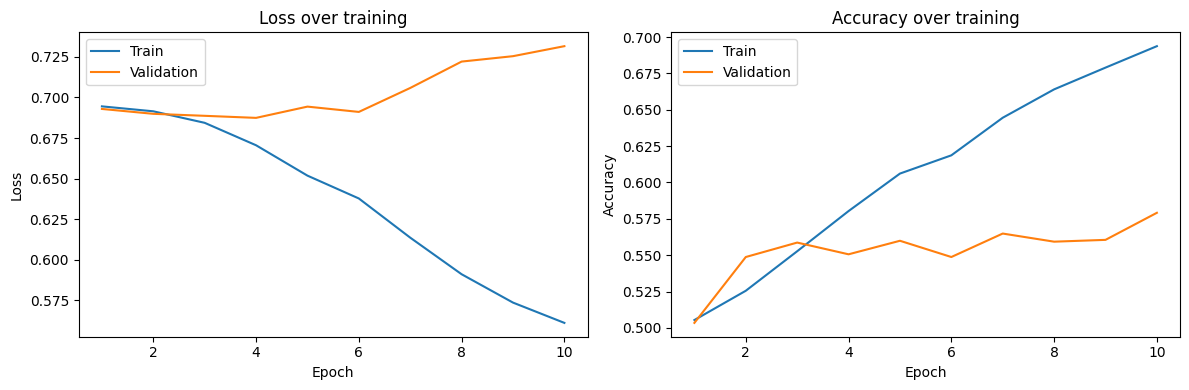

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss over training")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], label="Train")
axes[1].plot(epochs_range, history["val_acc"], label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy over training")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## 2.19 Loading the Best Checkpoint

The checkpoint with the highest validation accuracy (not necessarily the
final epoch) is reloaded here. All evaluation, ablation studies, and
attention analysis in Section 3 use this best-performing model rather than
whichever epoch happened to finish last.

In [ ]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()
print(f"Loaded best checkpoint (validation accuracy = {best_val_acc:.4f})")

Loaded best checkpoint (validation accuracy = 0.5791)


# 3.Testing and Evaluation


## 3.1 Test Set Preparation

"test_examples" / "test_labels" (loaded in Section 1.1, never touched since)
are now wrapped into a Dataset/DataLoader. This is the first and only time
the test set is used.

In [ ]:
test_dataset = PIQADataset(test_examples, test_labels, vocab)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print("Test batches:", len(test_loader))

Test batches: 58


## 3.2 Shared Evaluation Helpers


"forward_logits" normalises the output of any model variant (the main
model returns (logits, attention1, attention2); ablation models below
return "logits" only) so the same evaluation code works for all of them.
"collect_predictions" gathers predictions/labels across a full loader,
used for precision/recall/F1 and the confusion matrix.

In [ ]:
def forward_logits(model, goal_ids, sol1_ids, sol2_ids):
    output = model(goal_ids, sol1_ids, sol2_ids)
    if isinstance(output, tuple):
        return output[0]
    return output


def run_epoch_generic(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_training else torch.no_grad()

    with context:
        for batch in loader:
            goal_ids = batch["goal_ids"].to(device)
            sol1_ids = batch["sol1_ids"].to(device)
            sol2_ids = batch["sol2_ids"].to(device)
            labels = batch["labels"].to(device)

            if is_training:
                optimizer.zero_grad()

            logits = forward_logits(model, goal_ids, sol1_ids, sol2_ids)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = torch.argmax(logits, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def collect_predictions(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            goal_ids = batch["goal_ids"].to(device)
            sol1_ids = batch["sol1_ids"].to(device)
            sol2_ids = batch["sol2_ids"].to(device)
            labels = batch["labels"].to(device)

            logits = forward_logits(model, goal_ids, sol1_ids, sol2_ids)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    return all_preds, all_labels

## 3.3 Final Test Evaluation : Main Model

This is the only evaluation of the main model on the test set, using the
best checkpoint reloaded in Section 2.19.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_acc = run_epoch_generic(model, test_loader, criterion)
print(f"Main model — Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

main_preds, main_labels = collect_predictions(model, test_loader)
print("\nClassification report (main model):")
print(classification_report(main_labels, main_preds, target_names=["sol1", "sol2"]))
print("Confusion matrix:")
print(confusion_matrix(main_labels, main_preds))

Main model — Test loss: 0.7104 | Test accuracy: 0.5860

Classification report (main model):
              precision    recall  f1-score   support

        sol1       0.58      0.59      0.59       910
        sol2       0.59      0.58      0.59       928

    accuracy                           0.59      1838
   macro avg       0.59      0.59      0.59      1838
weighted avg       0.59      0.59      0.59      1838

Confusion matrix:
[[537 373]
 [388 540]]


## 3.4 Baseline 1 : Majority-Class Baseline

A trivial floor: always predict the majority label from the training set.
Any model that cannot beat this has learned nothing useful.

In [ ]:
from collections import Counter
from sklearn.metrics import accuracy_score

majority_label = Counter(train_labels).most_common(1)[0][0]
majority_preds = [majority_label] * len(test_labels)
majority_acc = accuracy_score(test_labels, majority_preds)

print(f"Majority-class baseline — always predicts {majority_label} — test accuracy: {majority_acc:.4f}")

Majority-class baseline — always predicts 1 — test accuracy: 0.5049


## 3.5 Baseline 2 : TF-IDF Cosine-Similarity Heuristic

An unsupervised baseline requiring no training: for each example, predict
whichever solution's TF-IDF vector is more similar (cosine similarity) to
the goal's TF-IDF vector. This tests how far pure lexical overlap gets you
on a physical-commonsense task like PIQA, where the correct answer often
has no special word overlap with the goal.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

train_goal_texts = [ex["goal"] for ex in train_examples]
train_sol1_texts = [ex["sol1"] for ex in train_examples]
train_sol2_texts = [ex["sol2"] for ex in train_examples]

test_goal_texts = [ex["goal"] for ex in test_examples]
test_sol1_texts = [ex["sol1"] for ex in test_examples]
test_sol2_texts = [ex["sol2"] for ex in test_examples]

tfidf = TfidfVectorizer(max_features=5000, stop_words="english")
tfidf.fit(train_goal_texts + train_sol1_texts + train_sol2_texts)

test_goal_vec = tfidf.transform(test_goal_texts)
test_sol1_vec = tfidf.transform(test_sol1_texts)
test_sol2_vec = tfidf.transform(test_sol2_texts)

sim_sol1 = cosine_similarity(test_goal_vec, test_sol1_vec).diagonal()
sim_sol2 = cosine_similarity(test_goal_vec, test_sol2_vec).diagonal()

similarity_preds = (sim_sol2 > sim_sol1).astype(int)
similarity_acc = accuracy_score(test_labels, similarity_preds)

print(f"TF-IDF cosine-similarity heuristic — test accuracy: {similarity_acc:.4f}")

TF-IDF cosine-similarity heuristic — test accuracy: 0.5136


## 3.6 Baseline 3 : TF-IDF + Logistic Regression

A supervised classical-ML baseline: concatenate TF-IDF features for goal,
sol1, and sol2, and train a logistic regression classifier to predict the
label directly. This represents a "bag-of-words with supervision" point of
comparison, between the unsupervised heuristic above and the main neural
model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack

train_goal_vec = tfidf.transform(train_goal_texts)
train_sol1_vec = tfidf.transform(train_sol1_texts)
train_sol2_vec = tfidf.transform(train_sol2_texts)

X_train = hstack([train_goal_vec, train_sol1_vec, train_sol2_vec])
X_test = hstack([test_goal_vec, test_sol1_vec, test_sol2_vec])

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, train_labels)

logreg_preds = logreg.predict(X_test)
logreg_acc = accuracy_score(test_labels, logreg_preds)

print(f"TF-IDF + Logistic Regression — test accuracy: {logreg_acc:.4f}")

TF-IDF + Logistic Regression — test accuracy: 0.5354


## 3.7 Overall Performance Comparison

In [ ]:
import pandas as pd

results_table = pd.DataFrame([
    {"Model": "Majority-class baseline", "Test Accuracy": majority_acc},
    {"Model": "TF-IDF similarity heuristic", "Test Accuracy": similarity_acc},
    {"Model": "TF-IDF + Logistic Regression", "Test Accuracy": logreg_acc},
    {"Model": "Main model (BiGRU + cross-attention)", "Test Accuracy": test_acc},
])
results_table = results_table.sort_values("Test Accuracy").reset_index(drop=True)
print(results_table.to_string(index=False))

                               Model  Test Accuracy
             Majority-class baseline       0.504897
         TF-IDF similarity heuristic       0.513602
        TF-IDF + Logistic Regression       0.535365
Main model (BiGRU + cross-attention)       0.585963


## 3.8 Ablation 1 : Removing Cross-Attention

Replaces cross-attention + interaction fusion with independent mean
pooling of the goal and solution, concatenated with their elementwise
product and absolute difference (same fusion width as the main model).
This isolates the contribution of letting solution tokens attend over the
goal, versus just pooling both independently.

In [ ]:
class PIQAModelNoAttention(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, pad_idx, dropout=0.3):
        super().__init__()
        self.pad_idx = pad_idx
        self.encoder = BiGRUEncoder(vocab_size, embedding_dim, hidden_dim, pad_idx, dropout)

        encoded_dim = hidden_dim * 2
        fusion_dim = encoded_dim * 4

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def score_candidate(self, goal_encoded, solution_encoded, goal_mask, solution_mask):
        pooled_goal = masked_mean_pooling(goal_encoded, goal_mask)
        pooled_solution = masked_mean_pooling(solution_encoded, solution_mask)

        fused = torch.cat([
            pooled_solution,
            pooled_goal,
            pooled_solution * pooled_goal,
            torch.abs(pooled_solution - pooled_goal)
        ], dim=-1)

        return self.classifier(fused)

    def forward(self, goal_ids, sol1_ids, sol2_ids):
        goal_mask = goal_ids != self.pad_idx
        sol1_mask = sol1_ids != self.pad_idx
        sol2_mask = sol2_ids != self.pad_idx

        goal_encoded = self.encoder(goal_ids)
        sol1_encoded = self.encoder(sol1_ids)
        sol2_encoded = self.encoder(sol2_ids)

        score1 = self.score_candidate(goal_encoded, sol1_encoded, goal_mask, sol1_mask)
        score2 = self.score_candidate(goal_encoded, sol2_encoded, goal_mask, sol2_mask)

        return torch.cat([score1, score2], dim=1)

## 3.9 Ablation 1 : Training and Evaluation

Trained under identical settings (epochs, optimizer, batch size) to the
main model, so the comparison isolates the architectural change.

In [ ]:
import torch.optim as optim
ablation1_model = PIQAModelNoAttention(
    vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM, pad_idx=pad_idx, dropout=DROPOUT
).to(device)

ablation1_optimizer = optim.Adam(ablation1_model.parameters(), lr=LEARNING_RATE)

ablation1_best_val_acc = 0.0
ABLATION1_PATH = "ablation1_no_attention.pt"

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch_generic(ablation1_model, train_loader, criterion, ablation1_optimizer)
    va_loss, va_acc = run_epoch_generic(ablation1_model, val_loader, criterion)

    print(f"[No-Attention] Epoch {epoch:2d}/{NUM_EPOCHS} | train_acc={tr_acc:.4f} | val_acc={va_acc:.4f}")

    if va_acc > ablation1_best_val_acc:
        ablation1_best_val_acc = va_acc
        torch.save(ablation1_model.state_dict(), ABLATION1_PATH)

ablation1_model.load_state_dict(torch.load(ABLATION1_PATH, map_location=device))
ablation1_test_loss, ablation1_test_acc = run_epoch_generic(ablation1_model, test_loader, criterion)
print(f"\n[No-Attention] Best val accuracy: {ablation1_best_val_acc:.4f} | Test accuracy: {ablation1_test_acc:.4f}")

[No-Attention] Epoch  1/10 | train_acc=0.5085 | val_acc=0.5301
[No-Attention] Epoch  2/10 | train_acc=0.5337 | val_acc=0.5419
[No-Attention] Epoch  3/10 | train_acc=0.5662 | val_acc=0.5289
[No-Attention] Epoch  4/10 | train_acc=0.6038 | val_acc=0.5289
[No-Attention] Epoch  5/10 | train_acc=0.6313 | val_acc=0.5407
[No-Attention] Epoch  6/10 | train_acc=0.6660 | val_acc=0.5351
[No-Attention] Epoch  7/10 | train_acc=0.6846 | val_acc=0.5431
[No-Attention] Epoch  8/10 | train_acc=0.7124 | val_acc=0.5587
[No-Attention] Epoch  9/10 | train_acc=0.7253 | val_acc=0.5531
[No-Attention] Epoch 10/10 | train_acc=0.7358 | val_acc=0.5525

[No-Attention] Best val accuracy: 0.5587 | Test accuracy: 0.5713


## 3.10 Ablation 2 : Unidirectional GRU

Replaces the shared bidirectional GRU with a unidirectional GRU (hidden
size doubled so the output width still matches `hidden_dim * 2`, keeping
cross-attention/fusion/scoring unchanged). Isolates the contribution of
bidirectionality in the encoder.

In [ ]:
class UniGRUEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, pad_idx, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim * 2,  # doubled to match BiGRU's output width
            batch_first=True,
            bidirectional=False
        )

    def forward(self, input_ids):
        embedded = self.dropout(self.embedding(input_ids))
        encoded, _ = self.gru(embedded)
        return encoded


class PIQAModelUniGRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, pad_idx, dropout=0.3):
        super().__init__()
        self.pad_idx = pad_idx
        self.encoder = UniGRUEncoder(vocab_size, embedding_dim, hidden_dim, pad_idx, dropout)
        self.attention = CrossAttention()
        self.scorer = CandidateScorer(hidden_dim=hidden_dim, dropout=dropout)

    def score_candidate(self, goal_encoded, solution_encoded, goal_mask, solution_mask):
        attended_goal, attention_weights = self.attention(solution_encoded, goal_encoded, goal_mask)
        fused = interaction_fusion(solution_encoded, attended_goal)
        score = self.scorer(fused, solution_mask)
        return score, attention_weights

    def forward(self, goal_ids, sol1_ids, sol2_ids):
        goal_mask = goal_ids != self.pad_idx
        sol1_mask = sol1_ids != self.pad_idx
        sol2_mask = sol2_ids != self.pad_idx

        goal_encoded = self.encoder(goal_ids)
        sol1_encoded = self.encoder(sol1_ids)
        sol2_encoded = self.encoder(sol2_ids)

        score1, attention1 = self.score_candidate(goal_encoded, sol1_encoded, goal_mask, sol1_mask)
        score2, attention2 = self.score_candidate(goal_encoded, sol2_encoded, goal_mask, sol2_mask)

        return torch.cat([score1, score2], dim=1), attention1, attention2

## 3.11 Ablation 2 : Training and Evaluation

In [ ]:
ablation2_model = PIQAModelUniGRU(
    vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM, pad_idx=pad_idx, dropout=DROPOUT
).to(device)

ablation2_optimizer = optim.Adam(ablation2_model.parameters(), lr=LEARNING_RATE)

ablation2_best_val_acc = 0.0
ABLATION2_PATH = "ablation2_unigru.pt"

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch_generic(ablation2_model, train_loader, criterion, ablation2_optimizer)
    va_loss, va_acc = run_epoch_generic(ablation2_model, val_loader, criterion)

    print(f"[Uni-GRU] Epoch {epoch:2d}/{NUM_EPOCHS} | train_acc={tr_acc:.4f} | val_acc={va_acc:.4f}")

    if va_acc > ablation2_best_val_acc:
        ablation2_best_val_acc = va_acc
        torch.save(ablation2_model.state_dict(), ABLATION2_PATH)

ablation2_model.load_state_dict(torch.load(ABLATION2_PATH, map_location=device))
ablation2_test_loss, ablation2_test_acc = run_epoch_generic(ablation2_model, test_loader, criterion)
print(f"\n[Uni-GRU] Best val accuracy: {ablation2_best_val_acc:.4f} | Test accuracy: {ablation2_test_acc:.4f}")

[Uni-GRU] Epoch  1/10 | train_acc=0.5009 | val_acc=0.5208
[Uni-GRU] Epoch  2/10 | train_acc=0.5318 | val_acc=0.5500
[Uni-GRU] Epoch  3/10 | train_acc=0.5457 | val_acc=0.5469
[Uni-GRU] Epoch  4/10 | train_acc=0.5698 | val_acc=0.5680
[Uni-GRU] Epoch  5/10 | train_acc=0.5952 | val_acc=0.5574
[Uni-GRU] Epoch  6/10 | train_acc=0.6249 | val_acc=0.5661
[Uni-GRU] Epoch  7/10 | train_acc=0.6464 | val_acc=0.5667
[Uni-GRU] Epoch  8/10 | train_acc=0.6628 | val_acc=0.5556
[Uni-GRU] Epoch  9/10 | train_acc=0.6894 | val_acc=0.5698
[Uni-GRU] Epoch 10/10 | train_acc=0.7005 | val_acc=0.5729

[Uni-GRU] Best val accuracy: 0.5729 | Test accuracy: 0.5990


## 3.12 Ablation Results Summary

In [ ]:
ablation_table = pd.DataFrame([
    {"Model": "Main model (BiGRU + cross-attention)", "Test Accuracy": test_acc},
    {"Model": "Ablation: No cross-attention", "Test Accuracy": ablation1_test_acc},
    {"Model": "Ablation: Unidirectional GRU", "Test Accuracy": ablation2_test_acc},
])
print(ablation_table.to_string(index=False))

                               Model  Test Accuracy
Main model (BiGRU + cross-attention)       0.585963
        Ablation: No cross-attention       0.571273
        Ablation: Unidirectional GRU       0.599021


## 3.13 Qualitative Attention Analysis : Setup

Builds an id-to-word lookup so token IDs can be decoded back to text, and
selects a handful of correctly- and incorrectly-predicted test examples to
visualise.

In [ ]:
inv_vocab = {idx: word for word, idx in vocab.items()}

def decode(ids):
    return [inv_vocab.get(i, "<UNK>") for i in ids]

correct_idx = [i for i in range(len(main_preds)) if main_preds[i] == main_labels[i]]
incorrect_idx = [i for i in range(len(main_preds)) if main_preds[i] != main_labels[i]]

print(f"Correct test predictions: {len(correct_idx)} | Incorrect: {len(incorrect_idx)}")

example_indices = correct_idx[:2] + incorrect_idx[:2]
print("Example indices selected for visualisation:", example_indices)

Correct test predictions: 1077 | Incorrect: 761
Example indices selected for visualisation: [1, 2, 0, 3]


## 3.14 Qualitative Attention Analysis : Visualisation Function

Plots a heatmap of attention weights: rows are solution tokens, columns
are goal tokens, for the predicted solution's attention map.

In [ ]:
import numpy as np

def plot_attention(example_idx):
    ex = test_examples[example_idx]
    true_label = test_labels[example_idx]
    pred_label = main_preds[example_idx]

    goal_ids = torch.tensor([encode(ex["goal"], vocab)]).to(device)
    sol1_ids = torch.tensor([encode(ex["sol1"], vocab)]).to(device)
    sol2_ids = torch.tensor([encode(ex["sol2"], vocab)]).to(device)

    model.eval()
    with torch.no_grad():
        logits, attention1, attention2 = model(goal_ids, sol1_ids, sol2_ids)

    goal_tokens = decode(goal_ids[0].cpu().tolist())
    goal_tokens = [t for t in goal_tokens if t != "<PAD>"]

    predicted_attention = attention1 if pred_label == 0 else attention2
    predicted_sol_ids = sol1_ids if pred_label == 0 else sol2_ids
    sol_tokens = decode(predicted_sol_ids[0].cpu().tolist())
    sol_tokens = [t for t in sol_tokens if t != "<PAD>"]

    attn = predicted_attention[0, :len(sol_tokens), :len(goal_tokens)].cpu().numpy()

    fig, ax = plt.subplots(figsize=(max(6, len(goal_tokens) * 0.5), max(3, len(sol_tokens) * 0.4)))
    im = ax.imshow(attn, cmap="viridis", aspect="auto")

    ax.set_xticks(range(len(goal_tokens)))
    ax.set_xticklabels(goal_tokens, rotation=45, ha="right")
    ax.set_yticks(range(len(sol_tokens)))
    ax.set_yticklabels(sol_tokens)

    correctness = "CORRECT" if pred_label == true_label else "INCORRECT"
    ax.set_title(f"[{correctness}] True: sol{true_label+1} | Predicted: sol{pred_label+1}\nGoal: {ex['goal']}")

    fig.colorbar(im, ax=ax, label="Attention weight")
    plt.tight_layout()
    plt.savefig(f"attention_example_{example_idx}.png", dpi=150)
    plt.show()

## 3.15 Qualitative Attention Analysis : Example Plots

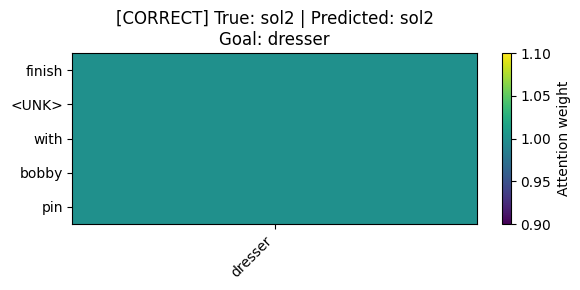

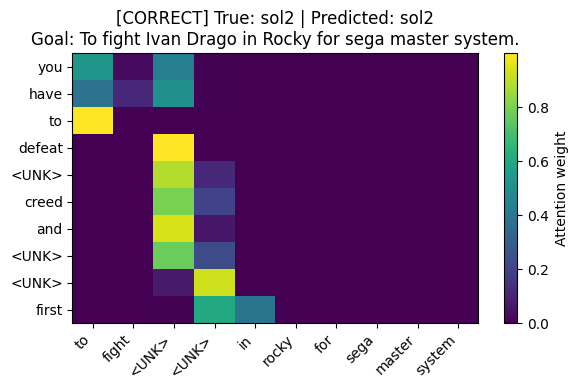

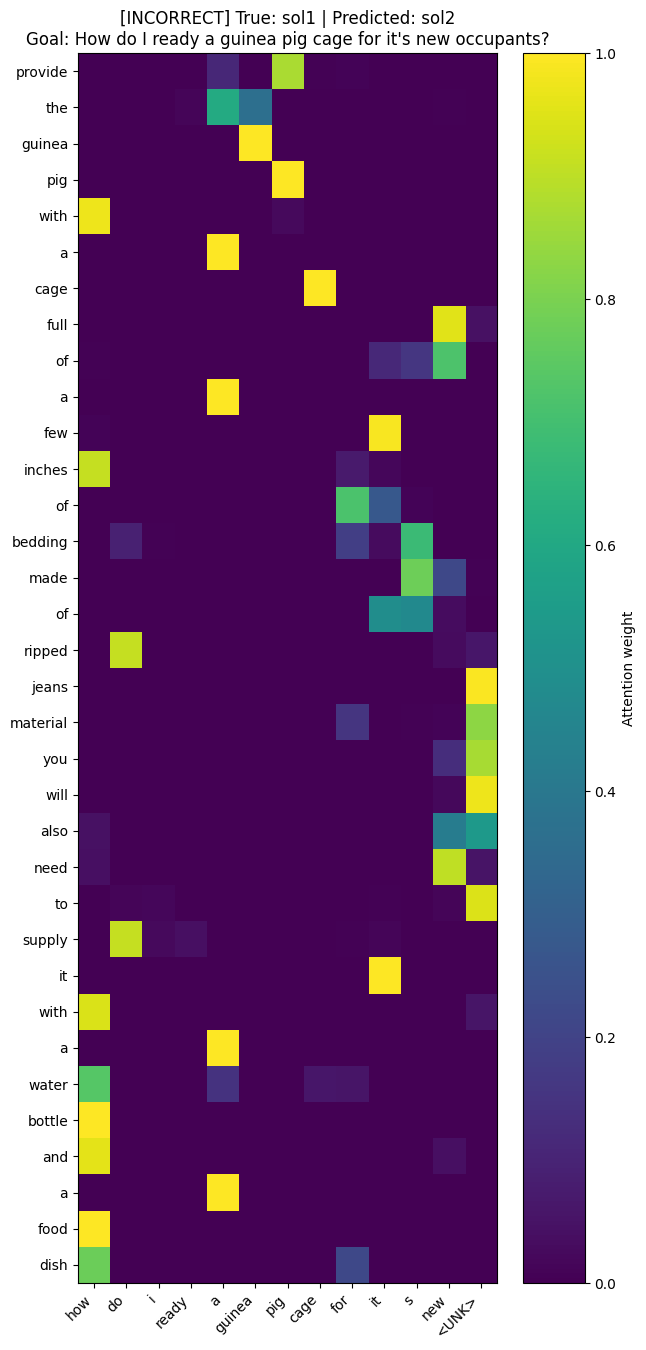

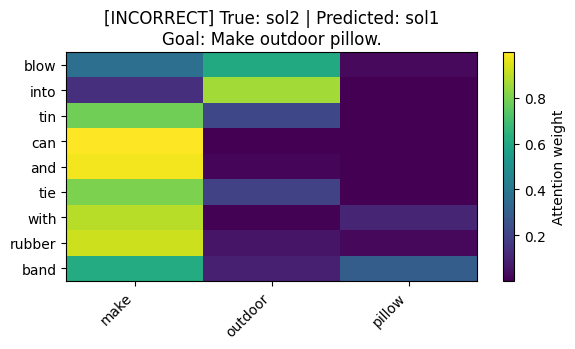

In [ ]:
for idx in example_indices:
    plot_attention(idx)